In [ ]:
pip install xgboost scikit-learn

Model Evaluation Metrics:
RMSE: 3.265
R² Score: 0.407


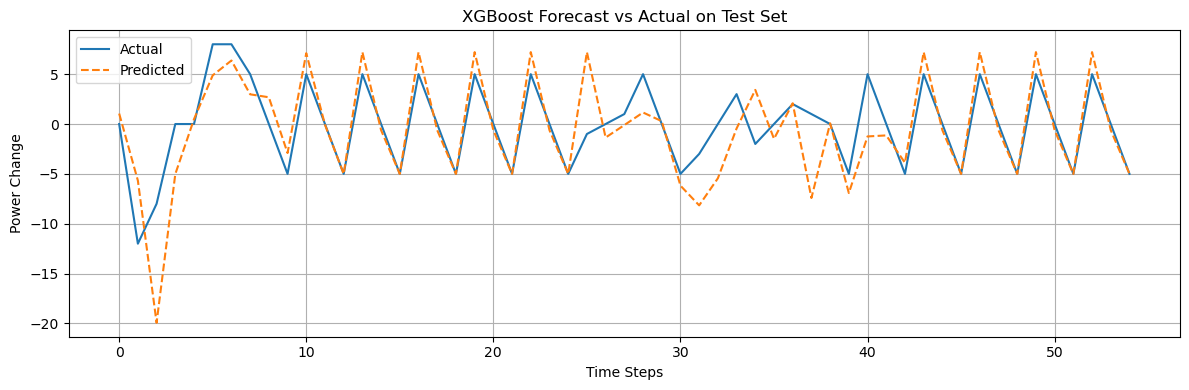

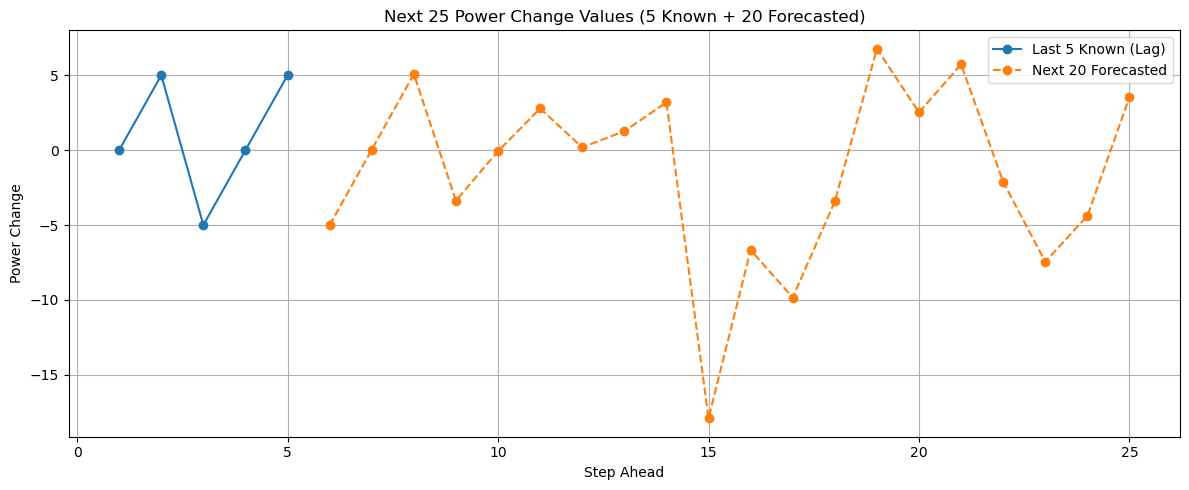


Forecasted Power Change for Next 20 Steps:
0     -5.007105
1      0.031376
2      5.073367
3     -3.368005
4     -0.069355
5      2.781983
6      0.184562
7      1.260720
8      3.191197
9    -17.899736
10    -6.671512
11    -9.838851
12    -3.423668
13     6.765614
14     2.524769
15     5.726485
16    -2.121883
17    -7.451504
18    -4.389077
19     3.539632
Name: Forecasted Power Change, dtype: float32

Summary Statistics for Forecasted Values:
count    20.000000
mean     -1.458050
std       6.023563
min     -17.899736
25%      -4.543584
50%      -0.018990
75%       2.884287
max       6.765614
Name: Forecasted Power Change, dtype: float64


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Step 1: Load and clean data
df = pd.read_csv("BOAs.csv")
df['powerChange'] = df['levelTo'] - df['levelFrom']
df['timeFrom'] = pd.to_datetime(df['timeFrom'], utc=True)
df = df.set_index('timeFrom').sort_index()
df = df.dropna(subset=['powerChange'])

# Step 2: Create lag features (t-1 to t-5)
def create_lagged_features(series, lags=5):
    df_lag = pd.DataFrame()
    for i in range(1, lags + 1):
        df_lag[f'lag_{i}'] = series.shift(i)
    df_lag['target'] = series.values
    return df_lag.dropna()

lagged_df = create_lagged_features(df['powerChange'], lags=5)

# Step 3: Split into train and test sets
X = lagged_df.drop(columns=['target'])
y = lagged_df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.15)

# Step 4: Train XGBoost regressor
model = XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Step 5: Predict and evaluate
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Model Evaluation Metrics:")
print(f"RMSE: {rmse:.3f}")
print(f"R² Score: {r2:.3f}")

# Step 6: Plot actual vs predicted
plt.figure(figsize=(12, 4))
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted', linestyle='--')
plt.title("XGBoost Forecast vs Actual on Test Set")
plt.xlabel("Time Steps")
plt.ylabel("Power Change")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Step 7: Forecast next 20 steps using last 5 lags
future_input = X.iloc[-1].values.reshape(1, -1)
future_forecast = []

for _ in range(20):
    pred = model.predict(future_input)[0]
    future_forecast.append(pred)
    future_input = np.roll(future_input, -1)
    future_input[0, -1] = pred

# Step 8: Combine last 5 known with 20 future predictions for full 25-step series
last_known_5 = list(X.iloc[-1].values[-5:])
full_25_steps = last_known_5 + future_forecast

# Step 9: Plot the 25 steps
plt.figure(figsize=(12, 5))
plt.plot(range(1, 6), last_known_5, marker='o', label='Last 5 Known (Lag)')
plt.plot(range(6, 26), future_forecast, marker='o', linestyle='--', label='Next 20 Forecasted')
plt.title("Next 25 Power Change Values (5 Known + 20 Forecasted)")
plt.xlabel("Step Ahead")
plt.ylabel("Power Change")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Step 10: Print and summarize forecasted values
forecast_series = pd.Series(future_forecast, name='Forecasted Power Change')

print("\nForecasted Power Change for Next 20 Steps:")
print(forecast_series)

print("\nSummary Statistics for Forecasted Values:")
print(forecast_series.describe())

Validation Set Performance:
RMSE: 6.680, R²: 0.365

Test Set Performance:
RMSE: 3.156, R²: 0.446


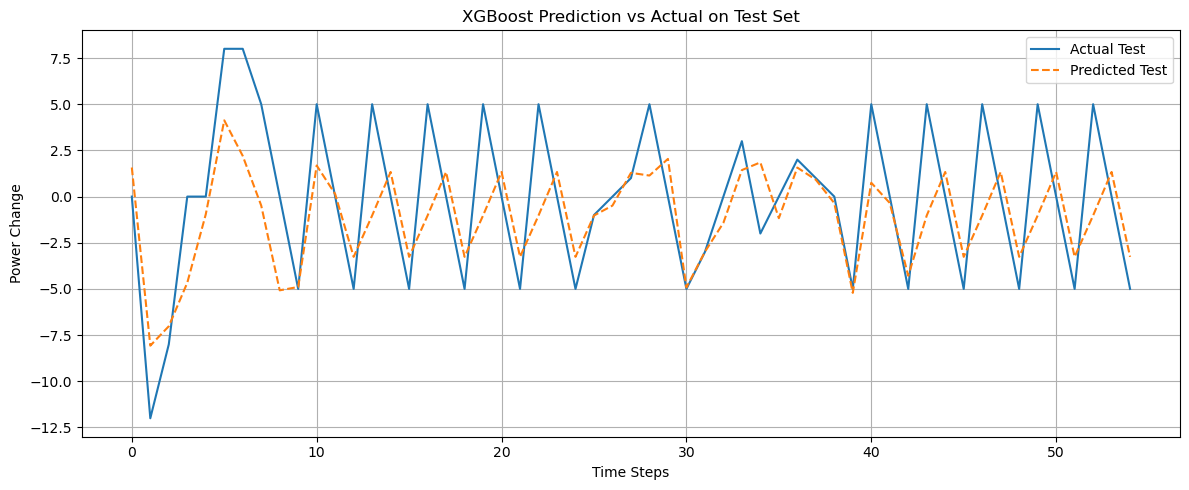

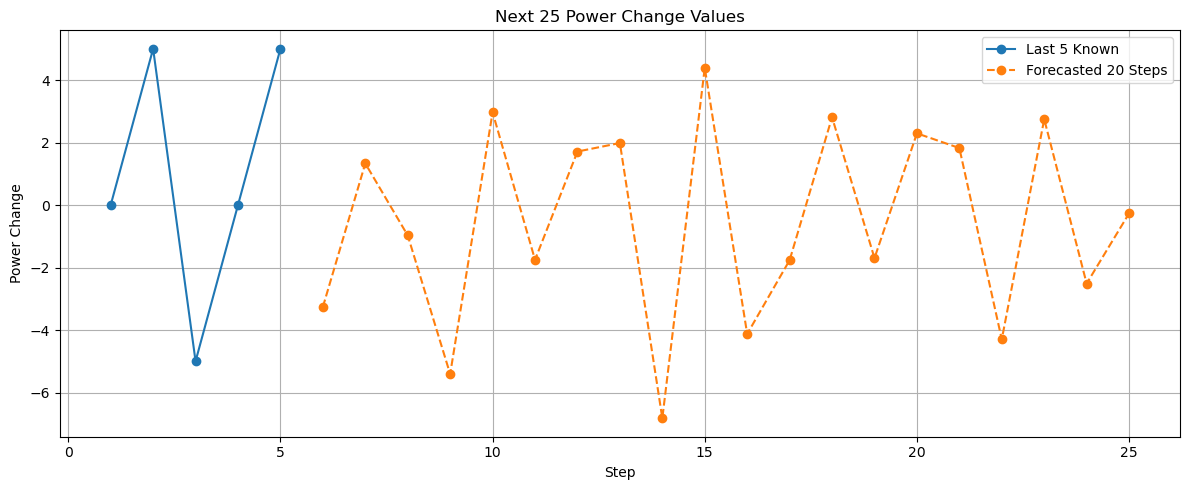


Forecasted Power Change for Next 20 Steps:
0    -3.262679
1     1.332268
2    -0.972187
3    -5.407642
4     2.968915
5    -1.752764
6     1.712013
7     1.984876
8    -6.822938
9     4.390141
10   -4.126271
11   -1.765097
12    2.810387
13   -1.698142
14    2.294792
15    1.823990
16   -4.299385
17    2.746199
18   -2.512196
19   -0.266516
Name: Forecasted Power Change, dtype: float32

Summary Statistics for Forecasted Values:
count    20.000000
mean     -0.541112
std       3.189291
min      -6.822938
25%      -2.699816
50%      -0.619351
75%       2.062355
max       4.390141
Name: Forecasted Power Change, dtype: float64


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Step 1: Load and clean data
df = pd.read_csv("BOAs.csv")
df['powerChange'] = df['levelTo'] - df['levelFrom']
df['timeFrom'] = pd.to_datetime(df['timeFrom'], utc=True)
df = df.set_index('timeFrom').sort_index()
df = df.dropna(subset=['powerChange'])

# Step 2: Create lag features (t-1 to t-5)
def create_lagged_features(series, lags=5):
    df_lag = pd.DataFrame()
    for i in range(1, lags + 1):
        df_lag[f'lag_{i}'] = series.shift(i)
    df_lag['target'] = series.values
    return df_lag.dropna()

lagged_df = create_lagged_features(df['powerChange'], lags=5)

# Step 3: Train-test-validation split (15% test, 10% validation from training)
X = lagged_df.drop(columns=['target'])
y = lagged_df['target']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, shuffle=False, test_size=0.15)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, shuffle=False, test_size=0.1)

# Step 4: Train XGBoost with tuned hyperparameters
model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0,
    reg_alpha=0.5,
    reg_lambda=1,
    random_state=42
)

model.fit(X_train, y_train)

# Step 5: Evaluate on validation and test sets
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("Validation Set Performance:")
print(f"RMSE: {val_rmse:.3f}, R²: {val_r2:.3f}")
print("\nTest Set Performance:")
print(f"RMSE: {test_rmse:.3f}, R²: {test_r2:.3f}")

# Step 6: Plot validation and test prediction comparison
plt.figure(figsize=(12, 5))
plt.plot(y_test.values, label='Actual Test')
plt.plot(y_test_pred, linestyle='--', label='Predicted Test')
plt.title("XGBoost Prediction vs Actual on Test Set")
plt.xlabel("Time Steps")
plt.ylabel("Power Change")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Step 7: Forecast 20 future steps (25 total with 5 lagged)
future_input = X.iloc[-1].values.reshape(1, -1)
future_forecast = []

for _ in range(20):
    pred = model.predict(future_input)[0]
    future_forecast.append(pred)
    future_input = np.roll(future_input, -1)
    future_input[0, -1] = pred

last_known_5 = list(X.iloc[-1].values[-5:])
all_25 = last_known_5 + future_forecast

plt.figure(figsize=(12, 5))
plt.plot(range(1, 6), last_known_5, marker='o', label='Last 5 Known')
plt.plot(range(6, 26), future_forecast, marker='o', linestyle='--', label='Forecasted 20 Steps')
plt.title("Next 25 Power Change Values")
plt.xlabel("Step")
plt.ylabel("Power Change")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Print and summarize
forecast_series = pd.Series(future_forecast, name='Forecasted Power Change')
print("\nForecasted Power Change for Next 20 Steps:")
print(forecast_series)
print("\nSummary Statistics for Forecasted Values:")
print(forecast_series.describe())